In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

In [2]:
df = pd.read_csv('C:/Users/Lenovo/Desktop/Python/Pandas/PandasCaseStudy/startup_funding.csv')

In [3]:
df.head(3)

,Sr No,Date dd/mm/yyyy,Startup Name,Industry Vertical,SubVertical,City Location,Investors Name,InvestmentnType,Amount in USD,Remarks
0,1,09/01/2020,BYJU’S,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,"20,00,00,000",NaN
1,2,13/01/2020,Shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,"80,48,394",NaN
2,3,09/01/2020,Mamaearth,E-commerce,Retailer of baby and toddler products,Bengaluru,Sequoia Capital India,Series B,"1,83,58,860",NaN


In [4]:
# cleaning process
df['Startup Name'] = df['Startup Name'].str.lower()

In [5]:
df[df['Startup Name'] ==  'https://www.wealthbucket.in/']

,Sr No,Date dd/mm/yyyy,Startup Name,Industry Vertical,SubVertical,City Location,Investors Name,InvestmentnType,Amount in USD,Remarks
3,4,02/01/2020,https://www.wealthbucket.in/,FinTech,Online Investment,New Delhi,Vinod Khatumal,Pre-series A,"30,00,000",NaN


In [6]:
df[df['Investors Name'] == 'Vinod Khatumal']

,Sr No,Date dd/mm/yyyy,Startup Name,Industry Vertical,SubVertical,City Location,Investors Name,InvestmentnType,Amount in USD,Remarks
3,4,02/01/2020,https://www.wealthbucket.in/,FinTech,Online Investment,New Delhi,Vinod Khatumal,Pre-series A,"30,00,000",NaN


In [7]:
df.head(3)

,Sr No,Date dd/mm/yyyy,Startup Name,Industry Vertical,SubVertical,City Location,Investors Name,InvestmentnType,Amount in USD,Remarks
0,1,09/01/2020,byju’s,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,"20,00,00,000",NaN
1,2,13/01/2020,shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,"80,48,394",NaN
2,3,09/01/2020,mamaearth,E-commerce,Retailer of baby and toddler products,Bengaluru,Sequoia Capital India,Series B,"1,83,58,860",NaN


In [8]:
df.set_index('Sr No', inplace=True)

In [9]:
df.drop(columns='Remarks' , inplace=True)

In [10]:
df.head()

,Date dd/mm/yyyy,Startup Name,Industry Vertical,SubVertical,City Location,Investors Name,InvestmentnType,Amount in USD
Sr No,,,,,,,,
1,09/01/2020,byju’s,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,"20,00,00,000"
2,13/01/2020,shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,"80,48,394"
3,09/01/2020,mamaearth,E-commerce,Retailer of baby and toddler products,Bengaluru,Sequoia Capital India,Series B,"1,83,58,860"
4,02/01/2020,https://www.wealthbucket.in/,FinTech,Online Investment,New Delhi,Vinod Khatumal,Pre-series A,"30,00,000"
5,02/01/2020,fashor,Fashion and Apparel,Embroiled Clothes For Women,Mumbai,Sprout Venture Partners,Seed Round,"18,00,000"


In [11]:

df['Date dd/mm/yyyy'] = df['Date dd/mm/yyyy'].str.strip()

In [12]:
df['Date dd/mm/yyyy'] =  pd.to_datetime(df['Date dd/mm/yyyy'] , dayfirst=True , errors='coerce')

In [13]:
df.columns


Index(['Date dd/mm/yyyy', 'Startup Name', 'Industry Vertical', 'SubVertical',
       'City  Location', 'Investors Name', 'InvestmentnType', 'Amount in USD'],
      dtype='str')

In [14]:
df.rename(columns={
       'Date dd/mm/yyyy' : 'date' ,
        'Startup Name' : 'startup' , 
        'Industry Vertical' : 'vertical' ,
          'SubVertical' : 'sub vertical' ,
            'City  Location' :  'city' ,
             'Investors Name' : 'investors' ,
             'InvestmentnType' : 'round' ,
             'Amount in USD' : 'amount(Cr)'
} , inplace=True)

In [15]:
df['amount(Cr)'] =  df['amount(Cr)'].fillna('0')


In [16]:
df['amount(Cr)'] = df['amount(Cr)'].str.strip().str.split(',').apply(lambda x : "".join(x))
df['amount(Cr)']= df['amount(Cr)'].apply(lambda x : '0' if x.isalpha() else x )
df['amount(Cr)'][~df['amount(Cr)'].str.isnumeric()]

Sr No
77              4889975.54
82              2739034.68
84             15109500.00
110              14342000+
2603    \\xc2\\xa020000000
2604    \\xc2\\xa016200000
2605         \\xc2\\xa0N/A
2606         \\xc2\\xa0N/A
2607      \\xc2\\xa0600000
2608      \\xc2\\xa0685000
2609    \\xc2\\xa019350000
2610     \\xc2\\xa05000000
2611    \\xc2\\xa010000000
2612         \\xc2\\xa0N/A
2614         \\xc2\\xa0N/A
Name: amount(Cr), dtype: str

In [17]:
def cleanAmount(text):
    text = text.strip() 
    text = "".join(text.split(',')) # join values to make one single
    if text.isalpha():
        text = '0'
    if not text.isnumeric()  and not '.' in text:
        text = '0'
    return text
    


In [18]:
df['amount(Cr)'] = df['amount(Cr)'].apply(cleanAmount)
df['amount(Cr)'] =df['amount(Cr)'].astype(float)

In [19]:
df['amount(Cr)']

Sr No
1       200000000.0
2         8048394.0
3        18358860.0
4         3000000.0
5         1800000.0
           ...     
3040      4500000.0
3041       825000.0
3042      1500000.0
3043            0.0
3044       140000.0
Name: amount(Cr), Length: 3044, dtype: float64

In [20]:
df['amount(Cr)'] = df['amount(Cr)'].astype('float')

In [21]:
# now converting to crore 
df['amount(Cr)'] = (df['amount(Cr)'] * 95.12) / 10000000

In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3044 entries, 1 to 3044
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          3036 non-null   datetime64[us]
 1   startup       3044 non-null   str           
 2   vertical      2873 non-null   str           
 3   sub vertical  2108 non-null   str           
 4   city          2864 non-null   str           
 5   investors     3020 non-null   str           
 6   round         3040 non-null   str           
 7   amount(Cr)    3044 non-null   float64       
dtypes: datetime64[us](1), float64(1), str(6)
memory usage: 492.3 KB


In [23]:
df['investors'] = df['investors'].fillna('Unkown')

In [24]:
df = df.dropna(subset=['date'  ,'vertical' ,'city','round'])

In [25]:
df.city.nunique()

110

In [26]:
df['city'] = df['city'].astype('category')

In [27]:
df.info()

<class 'pandas.DataFrame'>
Index: 2854 entries, 1 to 2873
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          2854 non-null   datetime64[us]
 1   startup       2854 non-null   str           
 2   vertical      2854 non-null   str           
 3   sub vertical  2097 non-null   str           
 4   city          2854 non-null   category      
 5   investors     2854 non-null   str           
 6   round         2854 non-null   str           
 7   amount(Cr)    2854 non-null   float64       
dtypes: category(1), datetime64[us](1), float64(1), str(5)
memory usage: 451.8 KB


In [28]:
temp_inves = df['investors'].str.strip().str.title().str.split(',').sum()
print(len(temp_inves))
print(len(set(temp_inves)))

5463
3419


In [29]:
for i in range(len(temp_inves)):
    temp_inves[i] = temp_inves[i].strip()

In [30]:
df.head(3)

,date,startup,vertical,sub vertical,city,investors,round,amount(Cr)
Sr No,,,,,,,,
1,2020-01-09,byju’s,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,1902.400000
2,2020-01-13,shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,76.556324
3,2020-01-09,mamaearth,E-commerce,Retailer of baby and toddler products,Bengaluru,Sequoia Capital India,Series B,174.629476


In [31]:
temp_inves

['Tiger Global Management',
 'Susquehanna Growth Equity',
 'Sequoia Capital India',
 'Vinod Khatumal',
 'Sprout Venture Partners',
 'Chiratae Ventures',
 'Ant Financial',
 'Sathguru Catalyzer Advisors',
 'Ping An Global Voyager Fund',
 'Mumbai Angels',
 'Ravikanth Reddy',
 'Saif Partners',
 'Spring Canter Investment Ltd.',
 'Paytm',
 'Nptk',
 'Sabre Partners And Neoplux',
 'Vertex Growth Fund',
 'Unkown',
 'Ruizheng Investment',
 'Manipal Education And Medical Group (Memg)',
 'Softbank Vision Fund',
 'Sequoia',
 'Capitalg',
 'Accel',
 'Sauce.Vc',
 'Rainforest Ventures',
 'Prime Venture Partners',
 'Letsventure',
 'Ps1 Venture And Globallogic Co-Founder Rajul Garg',
 'Rb Investments',
 'Dg Daiwa Ventures',
 'Dg Incubation',
 'Trifecta Capital Advisors',
 'Fintech',
 'Dream Incubator',
 'Altimeter Capital',
 'Sutter Hill Ventures',
 'Startup Buddy',
 'Amour Infrastructure',
 'Ackermans & Van Haaren',
 'Healthquad',
 'Rebright Partners',
 'Toppan Printing',
 'Matrix Partners',
 'Stellaris

In [32]:
# last 5 investments
df[df['investors'].str.contains('Tiger Global Management')].head()[['date' ,'city','startup','vertical','round','amount(Cr)']].reset_index(drop=True)

,date,city,startup,vertical,round,amount(Cr)
0,2020-01-09,Bengaluru,byju’s,E-Tech,Private Equity Round,1902.400
1,2019-08-22,Gurgaon,indwealth,FinTech,Venture Round,142.680
2,2019-07-11,Singapore,moglix,E-Commerce,Series D,570.720
3,2019-06-10,Haryana,okcredit,FinTech,Series A,147.436
4,2019-05-02,Hyderabad,zenoti,Saas,Series C,475.600


In [33]:
df[df['investors'].str.contains('Tiger Global Management' , case=False)].shape

(21, 8)

In [34]:
# biggest investments of an investor
top_investments = df[df['investors'].str.contains('Tiger Global Management')].groupby('startup' ,as_index=False)['amount(Cr)'].sum().sort_values(by='amount(Cr)' , ascending=False).reset_index(drop=True).head()
top_investments

,startup,amount(Cr)
0,byju’s,1902.40
1,saavn,951.20
2,shopclues,951.20
3,delhivery,808.52
4,moglix,570.72


<Axes: xlabel='startup'>

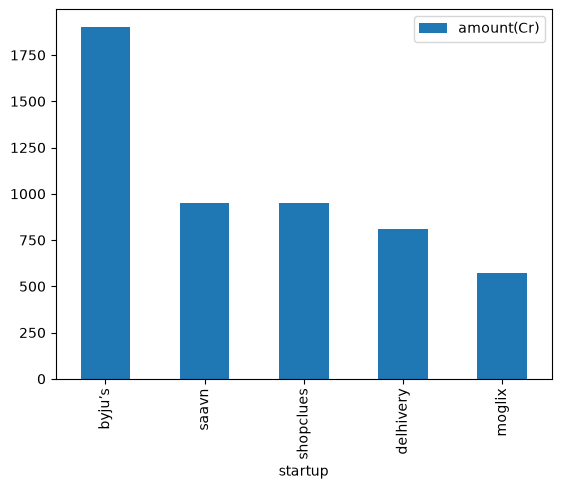

In [35]:
top_investments.set_index('startup').plot(kind='bar')

<BarContainer object of 5 artists>

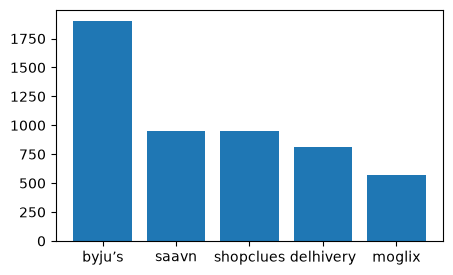

In [36]:
import matplotlib.pyplot as plt
# Change figsize to make it smaller (e.g., 4 inches wide by 3 inches tall)
fig, ax = plt.subplots(figsize=(5, 3)) 

ax.bar(top_investments['startup'], top_investments['amount(Cr)'])

In [37]:
df[df['amount(Cr)'] == 0]

,date,startup,vertical,sub vertical,city,investors,round,amount(Cr)
Sr No,,,,,,,,
21,2019-11-17,burger singh,Food and Beverage,Indian Burger Brand,Gurgaon,RB Investments,Venture,0.0
35,2019-10-21,the man company,Consumer Goods,Beauty and Grooming,Gurgaon,Ayushmann Khurana,Corporate Round,0.0
59,2019-08-19,mishry reviews,Services,Product Review,Gurgaon,Vir Sanghvi,Series A,0.0
90,2019-05-06,ola electric,Transport,Cabs,Bengaluru,Tata Sons,Series A,0.0
92,2019-05-05,styledotme,E-commerce,Fashion and Shopping,Delhi,Indian Angel Network and other angel investors...,Bridge Round,0.0
...,...,...,...,...,...,...,...,...
2856,2015-04-23,eazydiner,Restaurant reservation app,NaN,New Delhi,"Deepak Shahdadpuri, Gulpreet Kohli",Seed Funding,0.0
2857,2015-04-23,phone warrior,Spam Call block App,NaN,New Delhi,Lightspeed Ventures,Seed Funding,0.0
2862,2015-04-27,gibbs,Clean Tech,NaN,New Delhi,Infuse Ventures fund,Private Equity,0.0


In [38]:
# investments of an investor in verticals
df[df['investors'].str.contains('Sequoia Capital India')].groupby('vertical')['amount(Cr)'].sum().sort_values(ascending=False).head()

vertical
Consumer Internet    6013.486400
Technology            789.496000
E-Commerce            570.720000
E-commerce            174.629476
Logistics Tech        139.636160
Name: amount(Cr), dtype: float64

In [39]:
temp_df = df[df['investors'].str.contains('1Crowd')][['date' , 'amount(Cr)']]
temp_df

,date,amount(Cr)
Sr No,,
336,2018-03-19,4.756000
506,2017-11-21,3.804800
813,2017-05-10,5.707200
836,2017-05-22,4.756000
1331,2016-10-27,6.658400
1431,2016-08-08,1.902400
1438,2016-08-11,1.988008
1866,2016-03-15,1.426800


In [40]:
temp_df['year'] = temp_df['date'].dt.year
temp_df

,date,amount(Cr),year
Sr No,,,
336,2018-03-19,4.756000,2018
506,2017-11-21,3.804800,2017
813,2017-05-10,5.707200,2017
836,2017-05-22,4.756000,2017
1331,2016-10-27,6.658400,2016
1431,2016-08-08,1.902400,2016
1438,2016-08-11,1.988008,2016
1866,2016-03-15,1.426800,2016


In [41]:
year_df = temp_df[['date' , 'amount(Cr)']]
year_df['year'] = year_df['date'].dt.year
year_df.groupby('year')['amount(Cr)'].sum()


year
2016    11.975608
2017    14.268000
2018     4.756000
Name: amount(Cr), dtype: float64

<Axes: xlabel='year'>

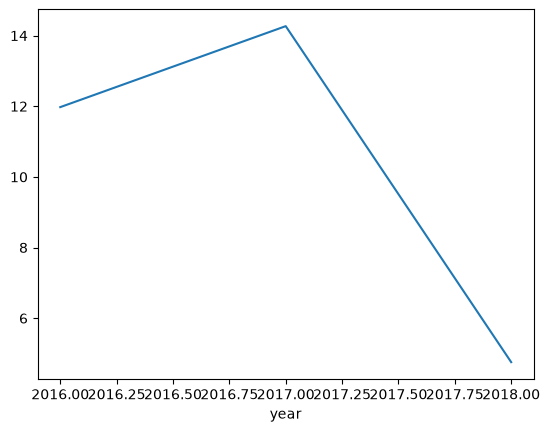

In [42]:
temp_df.groupby('year')['amount(Cr)'].sum().plot(kind='line' ,)

In [43]:
c= pd.Series([1,2,3,4])
c.empty

False

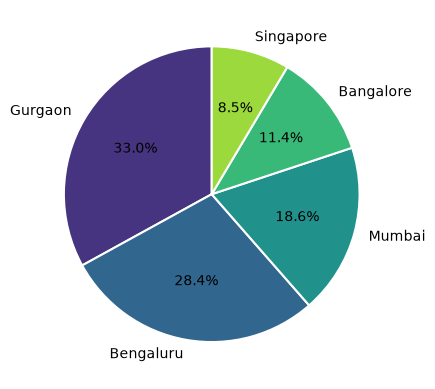

In [44]:
ct = df[df['investors'].str.contains('Tiger Global Management')].groupby('city')['amount(Cr)'].sum().sort_values(ascending=False)
ct = ct[ct != 0]
ct = ct.head(5)
fig,ax =plt.subplots()
n = len(ct.values)
colors = plt.get_cmap("viridis")(np.linspace(0.15, 0.85, n))
ax.pie(ct.values , labels=ct.index ,autopct='%1.1f%%',colors=colors ,startangle=90, wedgeprops={"edgecolor": "white", "linewidth": 1.5})




**general analysis**

In [45]:
# total investment in india  till 2022
round(df['amount(Cr)'].sum())

347843

In [46]:
# max funding for a startup till 2022
highest_funding_startup = df.groupby('startup')['amount(Cr)'].sum().sort_values(ascending=False).head(1)

In [47]:
# avg investment in startups
round(df.groupby('startup')['amount(Cr)'].sum().mean(),1)

np.float64(156.5)

In [48]:
df[df['startup'] != 0]['startup'].value_counts().sum()

np.int64(2854)

In [49]:
# each year month wise total investment and total number of startups in which funding was applied 
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month_name()

In [50]:
total_y_m_invs = df.groupby('year' )['amount(Cr)'].sum()

<Axes: xlabel='year'>

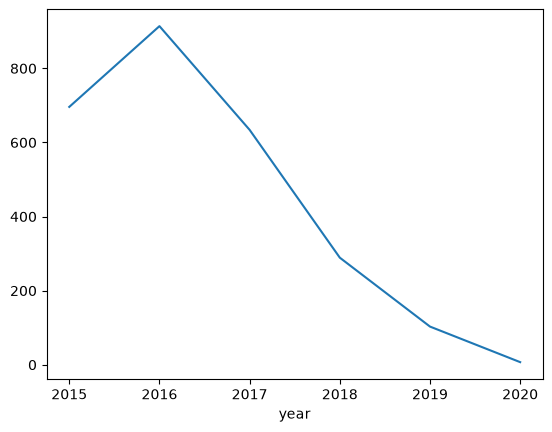

In [51]:
df.groupby('year')['startup'].nunique().plot()

<Axes: xlabel='year'>

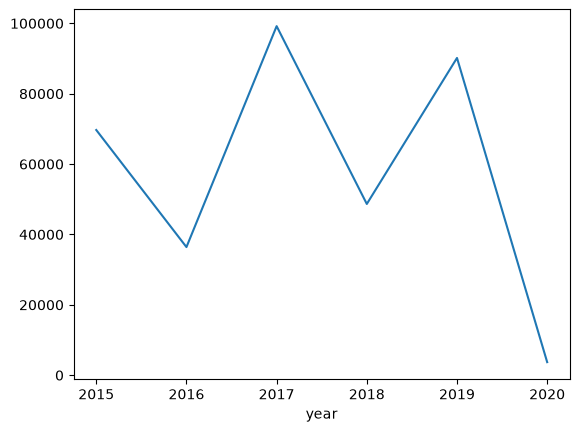

In [52]:
df.groupby('year' )['amount(Cr)'].sum().plot()

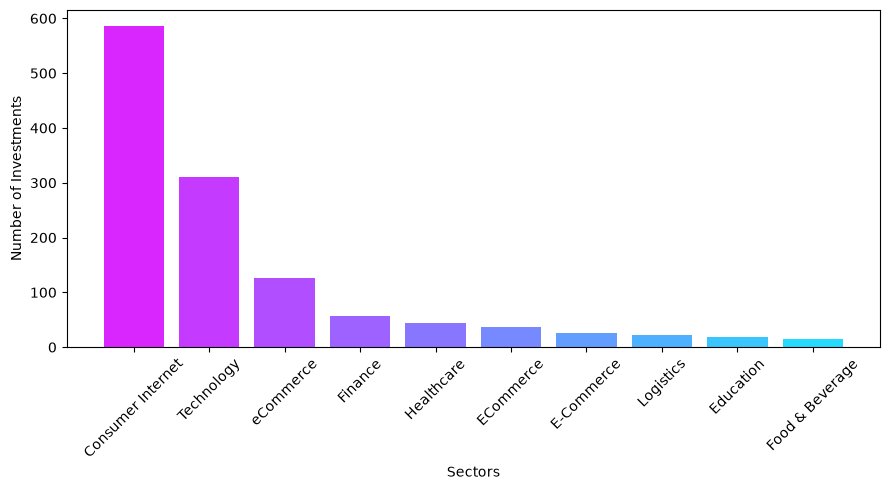

In [53]:
ct = df[df['amount(Cr)'] > 0]
ct = ct['vertical'].value_counts().head(10)

fig, ax = plt.subplots(figsize=(9, 5))
colors = plt.get_cmap("cool")(np.linspace(0.85,0.15 ,10))

ax.bar(x=ct.index, height=ct.values, color=colors)
ax.set_ylabel("Number of Investments")
ax.set_xlabel("Sectors")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [54]:
df.head(1)

,date,startup,vertical,sub vertical,city,investors,round,amount(Cr),year,month
Sr No,,,,,,,,,,
1,2020-01-09,byju’s,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,1902.4,2020,January


In [55]:
ct = df[df['investors'] != 'Unkown']
ct = ct.groupby('investors')['amount(Cr)'].sum().sort_values(ascending=False).head(10).reset_index()
ct

,investors,amount(Cr)
0,Westbridge Capital,37096.8000
1,Softbank,23780.0000
2,SoftBank Group,13906.5440
3,"Microsoft, eBay, Tencent Holdings",13316.8000
4,Vijay Shekhar Sharma,9513.4268
5,Steadview Capital and existing investors,6658.4000
6,"Alibaba Group, Ant Financial",6468.1600
7,"Altimeter Capital, DST Global",5564.5200
8,SoftBank Vision Fund,5050.8720
9,"Alibaba, Foxconn, Softbank",4756.0000


In [56]:
top =df.groupby(['year' ,'startup'] ,as_index=False)['amount(Cr)'].sum().sort_values(['year' ,'amount(Cr)'],ascending=[True,False]).drop_duplicates('year').reset_index(drop=True)

In [57]:
top

,year,startup,amount(Cr)
0,2015,flipkart.com,6658.4000
1,2016,snapdeal,1902.4000
2,2017,flipkart,38140.2664
3,2018,true north,5707.2000
4,2019,rapido bike taxi,37096.8000
5,2020,byju’s,1902.4000


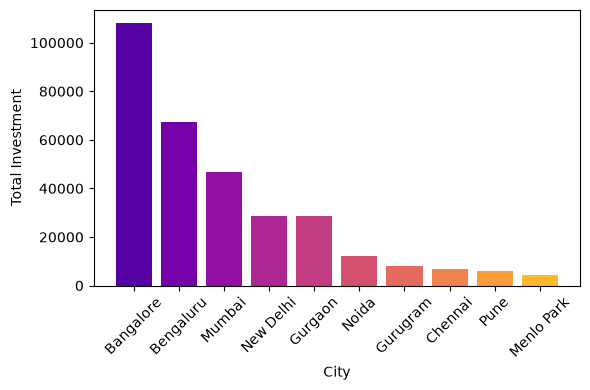

In [58]:
ctemp = df.groupby('city')['amount(Cr)'].sum().sort_values(ascending=False).head(10)
fig, ax = plt.subplots(figsize=(6, 4))
colors = plt.get_cmap("plasma")(np.linspace(0.15,0.85 ,10))

ax.bar(x=ctemp.index, height=ctemp.values, color=colors)
ax.set_ylabel("Total Investment")
ax.set_xlabel("City")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [59]:
df.head()

,date,startup,vertical,sub vertical,city,investors,round,amount(Cr),year,month
Sr No,,,,,,,,,,
1,2020-01-09,byju’s,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,1902.400000,2020,January
2,2020-01-13,shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,76.556324,2020,January
3,2020-01-09,mamaearth,E-commerce,Retailer of baby and toddler products,Bengaluru,Sequoia Capital India,Series B,174.629476,2020,January
4,2020-01-02,https://www.wealthbucket.in/,FinTech,Online Investment,New Delhi,Vinod Khatumal,Pre-series A,28.536000,2020,January
5,2020-01-02,fashor,Fashion and Apparel,Embroiled Clothes For Women,Mumbai,Sprout Venture Partners,Seed Round,17.121600,2020,January


In [60]:
# heat map 
# Quick code to map messy round names into clean, standardized categories
def clean_round(round_name):
    r = str(round_name).lower().strip()
    if 'seed' in r or 'angel' in r:
        return 'Seed / Angel'
    elif 'series a' in r or 'pre-series a' in r or 'pre series a' in r:
        return 'Series A / Pre-Series A'
    elif 'series b' in r:
        return 'Series B'
    elif 'series c' in r:
        return 'Series C'
    elif 'series d' in r:
        return 'Series D'
    elif 'series e' in r or 'series f' in r or 'series g' in r or 'series h' in r or 'series j' in r:
        return 'Late Stage Series (E-J)'
    elif 'debt' in r or 'loan' in r:
        return 'Debt / Loan'
    elif 'private equity' in r or 'private' in r or 'equity' in r:
        return 'Private Equity / Equity'
    else:
        return 'Other / Venture'

df['clean_round'] = df['round'].apply(clean_round)

In [61]:
list(df['vertical'].unique())

['E-Tech',
 'Transportation',
 'E-commerce',
 'FinTech',
 'Fashion and Apparel',
 'Logistics',
 'Hospitality',
 'Technology',
 'E-Commerce',
 'Aerospace',
 'B2B-focused foodtech startup',
 'Finance',
 'Video',
 'Gaming',
 'Software',
 'Health and wellness',
 'Education',
 'Food and Beverage',
 'Health and Wellness',
 'B2B Marketing',
 'Video Games',
 'SaaS',
 'Last Mile Transportation',
 'Healthcare',
 'Customer Service',
 'B2B',
 'Consumer Goods',
 'Advertising, Marketing',
 'IoT',
 'Information Technology',
 'Consumer Technology',
 'Accounting',
 'Retail',
 'Customer Service Platform',
 'Automotive',
 'EdTech',
 'Services',
 'Compliance',
 'Transport',
 'Artificial Intelligence',
 'Tech',
 'Health Care',
 'Luxury Label',
 'Waste Management Service',
 'Deep-Tech',
 'Energy',
 'Digital Media',
 'Saas',
 'Automobile',
 'Agtech',
 'Social Media',
 'Fintech',
 'Edtech',
 'AI',
 'Ecommerce',
 'Nanotechnology',
 'Services Platform',
 'Travel Tech',
 'Online Education',
 'Online Marketplace'

In [62]:
# Assuming your list of verticals is stored in a variable called `verticals_list`
unique_verticals = set(v.strip().title() for v in df['vertical'])
print("Total raw entries:", len(df['vertical']))
print("Unique standardized verticals:", len(unique_verticals))

Total raw entries: 2854
Unique standardized verticals: 794


In [63]:
df[df['city'].str.contains(r'[/\\\-\+!~;:?]')]['city']

Sr No
89            Mumbai/Bengaluru
114            India/Singapore
118                   India/US
141           Mumbai/Bengaluru
142                   India/US
1351        Bangalore/ Bangkok
1741           SFO / Bangalore
1825       Seattle / Bangalore
1859              Pune/Seattle
1912              Pune / Dubai
1918           Bangalore / SFO
2070            New Delhi / US
2071               Mumbai / UK
2149             Hyderabad/USA
2163     Bangalore / Palo Alto
2174               Mumbai / NY
2207                 USA/India
2224        Bangalore/ Bangkok
2230             Goa/Hyderabad
2244         Noida / Singapore
2256                 Pune / US
2269        Chennai/ Singapore
2315          Pune / Singapore
2320     Bangalore / San Mateo
2350           New York/ India
2415                  US/India
2450             Gurgaon / SFO
2467           Bangalore / USA
2503        New Delhi/ Houston
2513            New Delhi / US
2594           Mumbai / Global
2595                India / US
26

In [64]:
import re

def clean_cities(city):
    if not isinstance(city, str):
        return ""
    
    # Convert to lowercase and strip initial whitespace
    city = city.strip().lower()
    
    # Use regex to catch various forms: \xc2, xc2, \xa0, \\xc2, or actual non-breaking spaces (\u00a0)
    city = re.sub(r'\\*xc2\\*|\\*xa0|\u00a0', '', city)
    
    # Handle slashes if present
    city = re.split(r'[/,&]', city)[0]
        
    # Clean up any extra spacing left behind and format
    city = re.sub(r'\s+', ' ', city)
    return city.title().strip()

In [65]:
ctemp = df.pivot_table(index='month' , columns='year' , values='amount(Cr)' , aggfunc='sum',fill_value=0)
ctemp

year,2015,2016,2017,2018,2019,2020
month,,,,,,
April,9326.516000,2415.477280,6966.541240,1884.115463,1101.426393,0.0000
August,10119.017792,5080.254568,26140.298168,7698.582962,43106.196240,0.0000
December,2909.273736,1781.055416,2705.403040,548.985080,4536.272800,0.0000
February,0.000000,3153.137636,2805.650008,11521.098225,2155.419200,0.0000
January,0.000000,6657.258560,2408.757052,3304.227195,1303.144000,3711.6514
July,14355.434304,2221.499064,1595.200448,5250.414736,2823.110283,0.0000
June,4965.206928,1898.966168,3279.908816,3723.710200,2753.949434,0.0000
March,0.000000,2944.550015,21537.840872,2777.056936,0.000000,0.0000
May,3045.124120,3232.558080,16994.795528,1007.197144,3890.109323,0.0000


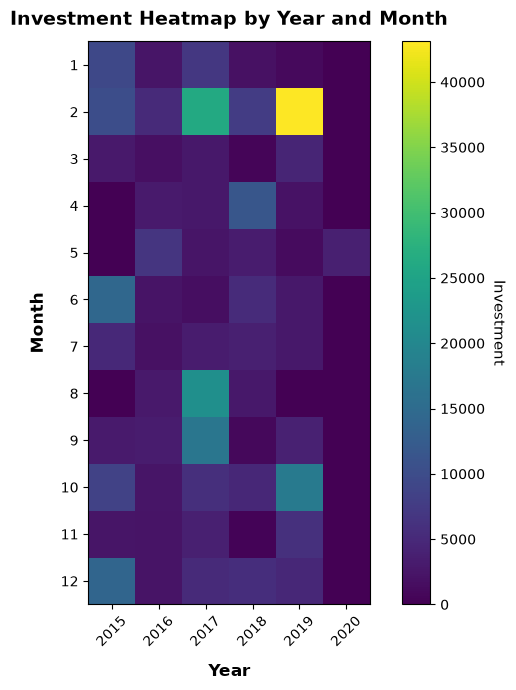

In [66]:
# Use a more square figure size
plt.figure(figsize=(7, 7))

# aspect='equal' keeps cells nicely proportioned instead of stretched
im = plt.imshow(ctemp, cmap='viridis', aspect='equal', interpolation='nearest')

# X and Y ticks (rotate x-ticks to give year names breathing room)
plt.xticks(np.arange(6), df['year'].sort_values().unique(), fontsize=10, rotation=45)
plt.yticks(np.arange(12), np.arange(1, 13), fontsize=10)

# Labels and Title
plt.xlabel('Year', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('Month', fontsize=12, fontweight='bold', labelpad=10)
plt.title('Investment Heatmap by Year and Month', fontsize=14, pad=12, fontweight='bold')

# Colorbar matching your data
cbar = plt.colorbar(im)
cbar.set_label('Investment', rotation=270, labelpad=15, fontsize=11)

# Clean layout so labels aren't cut off
plt.tight_layout()
plt.show()

In [67]:
df = pd.read_csv('C:/Users/Lenovo/Desktop/Python/Project1/cleaned_data.csv')
df['date'] = pd.to_datetime(df['date'])

In [68]:
df['year'] = df['date'].dt.year

In [69]:
df[df['startup'] == 'Shuttl']

,date,startup,vertical,sub vertical,city,investors,round,amount(Cr),year
1,2020-01-13,Shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,76.556324,2020
107,2019-04-17,Shuttl,Transportation,Bus Aggregation,Gurugram,New Atlantic Ventures,Venture Round,47.560000,2019
217,2018-07-30,Shuttl,Consumer Internet,Bus Aggregation Platform,Gurugram,"Amazon Alexa Fund, Dentsu Ventures",Private Equity,104.632000,2018
2108,2015-12-03,Shuttl,App based Bus Pooling Services,NaN,Gurgaon,"Sequoia Capital, Times Internet, One more Fund",Private Equity,190.240000,2015


In [70]:
temp_df = df[df['startup'] == 'Shuttl']
list(temp_df['vertical'].unique())

['Transportation', 'Consumer Internet', 'App based Bus Pooling Services']

In [71]:
np.round(temp_df['amount(Cr)'].sum(),2) # total amount invested 
np.round(temp_df['amount(Cr)'].max(),2) # highest  investment 
# check for 0 

np.float64(190.24)

In [72]:
list(temp_df['sub vertical'].dropna().unique())

['App based shuttle service', 'Bus Aggregation', 'Bus Aggregation Platform']

In [73]:
location = list(temp_df['city'].dropna().unique())
location

['Gurgaon', 'Gurugram']

In [74]:
temp_df['investors'].str.strip().str.split(',')

1                             [Susquehanna Growth Equity]
107                               [New Atlantic Ventures]
217                 [Amazon Alexa Fund,  Dentsu Ventures]
2108    [Sequoia Capital,  Times Internet,  One more F...
Name: investors, dtype: object

In [75]:
def refine(lst):
    for i in range(len(lst)):
        lst[i] = lst[i].strip()
    return lst

In [76]:
investors_who_invested = set(temp_df['investors'].str.strip().str.split(',').apply(refine).sum())

In [77]:
vertical_investment = temp_df.groupby('vertical')['amount(Cr)'].sum()

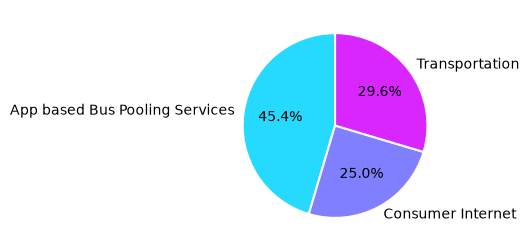

In [78]:
fig,ax =plt.subplots(figsize=(3,3))
n = len(vertical_investment.values)
colors = plt.get_cmap("cool")(np.linspace(0.15, 0.85, n))
ax.pie(vertical_investment.values , labels=vertical_investment.index ,autopct='%1.1f%%',colors=colors ,startangle=90, wedgeprops={"edgecolor": "white", "linewidth": 1.5})




In [79]:
temp_df

,date,startup,vertical,sub vertical,city,investors,round,amount(Cr),year
1,2020-01-13,Shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,76.556324,2020
107,2019-04-17,Shuttl,Transportation,Bus Aggregation,Gurugram,New Atlantic Ventures,Venture Round,47.560000,2019
217,2018-07-30,Shuttl,Consumer Internet,Bus Aggregation Platform,Gurugram,"Amazon Alexa Fund, Dentsu Ventures",Private Equity,104.632000,2018
2108,2015-12-03,Shuttl,App based Bus Pooling Services,NaN,Gurgaon,"Sequoia Capital, Times Internet, One more Fund",Private Equity,190.240000,2015


In [80]:
yearly_investment = temp_df.groupby('year')['amount(Cr)'].sum()
yearly_investment

year
2015    190.240000
2018    104.632000
2019     47.560000
2020     76.556324
Name: amount(Cr), dtype: float64

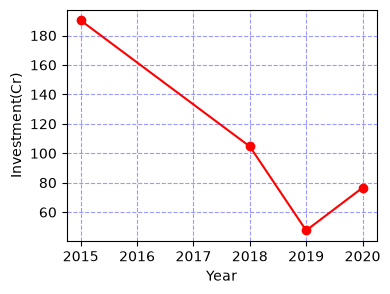

In [81]:
fig,ax = plt.subplots(figsize=(4,3))
ax.plot(yearly_investment,marker='o' , color='red')
ax.set_xlabel('Year')
ax.set_ylabel('Investment(Cr)')
ax.grid(True ,linestyle='--' , color='blue' , alpha=0.4)


### making similar investors feature

In [82]:
df.head(4)

,date,startup,vertical,sub vertical,city,investors,round,amount(Cr),year
0,2020-01-09,BYJU'S,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,1902.400000,2020
1,2020-01-13,Shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,76.556324,2020
2,2020-01-09,MamaEarth,E-commerce,Retailer of baby and toddler products,Bengaluru,Sequoia Capital India,Series B,174.629476,2020
3,2020-01-02,Wealthbucket,FinTech,Online Investment,New Delhi,Vinod Khatumal,Pre-series A,28.536000,2020


In [83]:
investor_temp= df[df['investors'].str.contains('Matrix Partners',case=False )]

In [84]:
investor_temp_startups =investor_temp['startup'].to_list()
investor_temp_verticals = investor_temp['vertical'].to_list()
investor_temp_subvericals = investor_temp['sub vertical'].to_list()
investor_temp_city = investor_temp['city'].to_list()

In [85]:

temp_df = df[df['startup'].isin(investor_temp_startups)]
if(investor_temp.shape[0] > 5):
  temp_df = temp_df[temp_df['vertical'].isin(investor_temp_verticals)]
if(investor_temp.shape[0] > 5):
  temp_df = temp_df[temp_df['sub vertical'].isin(investor_temp_subvericals)]
if(investor_temp.shape[0] > 5):
  temp_df = temp_df[temp_df['city'].isin(investor_temp_city)]
temp_df.sort_values(['year' ,'amount(Cr)'] ,ascending=[False , False],inplace=True)
lst = pd.Series(temp_df['investors'].str.split(',').sum())
lst[~lst.str.contains('Matrix Partners')].to_list()[:5]


[' Stellaris Venture Partners',
 ' Kalaari Capital',
 ' Sequoia India',
 'TPG',
 ' Norwest Venture Partners']

In [87]:
df.head(3)

,date,startup,vertical,sub vertical,city,investors,round,amount(Cr),year
0,2020-01-09,BYJU'S,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,1902.400000,2020
1,2020-01-13,Shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,76.556324,2020
2,2020-01-09,MamaEarth,E-commerce,Retailer of baby and toddler products,Bengaluru,Sequoia Capital India,Series B,174.629476,2020


In [97]:
fig = px.sunburst(df,path=['city' ,'vertical' ,'startup'] ,values='amount(Cr)',
                  color_discrete_sequence=px.colors.carto.Agsunset)
fig.update_traces(
    hovertemplate='<b>%{label}</b><br>Total investment: $%{value:.2f}<extra></extra>'
)
fig.update_layout(paper_bgcolor='black' , plot_bgcolor='white')

In [114]:
s_df = df[df['startup']== 'Ola']
px.pie(s_df,names='vertical' ,values='amount(Cr)',hole=0.2 ,width=600 ,height=450,
       color_discrete_sequence=px.colors.sequential.RdBu)

In [116]:
s_df.shape[0]

13